# Determining risk-neutral probabilities from option prices

The Breeden-Litzenberger formula states that:
$$\frac{\partial^2 C(K)}{\partial K^2} = e^{-rT}f_Q(K)$$
Where

| Variable | Meaning |
| - | - |
| $K$ | Strike |
| $r$ | risk-free rate |
| $T$ | time to expiry |
| $C(K)$ | Call price as a function of strike |
| $f_Q(K)$ | risk-neutral density at K |

So
$$f_Q(K) = e^{rT}\frac{\partial^2 C(K)}{\partial K^2}$$

# Demonstration in python

## Obtain current option data

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from datetime import date

In [2]:
ticker = yf.Ticker("MSFT")
r = 0.05

In [3]:
expirations = ticker.options
expiry = expirations[0] # choose the soonest option expiry date
T = (date.fromisoformat(expiry) - date.today()).days/365

In [4]:
expiry

'2026-03-02'

In [5]:
current_price = ticker.fast_info.last_price

option_chain = ticker.option_chain(expiry)
calls = option_chain.calls
strikes = calls["strike"].values
call_prices = calls["lastPrice"].values

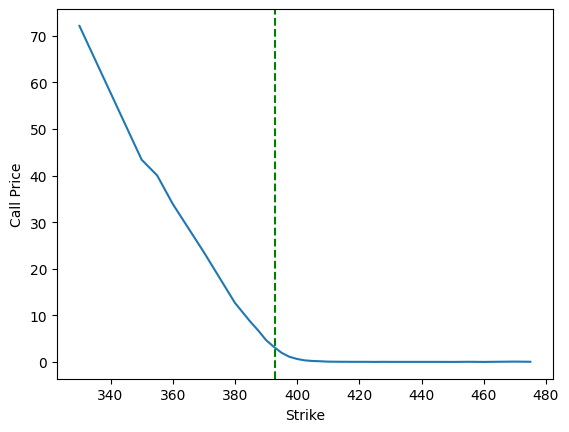

In [6]:
plt.plot(strikes, call_prices)
plt.ylabel("Call Price")
plt.xlabel("Strike")
plt.axvline(current_price, c="g", ls="--")

## Fit to Black-Scholes curve

In [7]:
def bs_call(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * scipy.stats.norm.cdf(d1) - K * np.exp(-r * T) * scipy.stats.norm.cdf(d2)

In [8]:
(sigma,), covariance = scipy.optimize.curve_fit(lambda K,sigma: bs_call(current_price, K, T, r, sigma), strikes, call_prices, p0=[1])

In [9]:
strike_space = np.linspace(min(strikes), max(strikes), 1000)

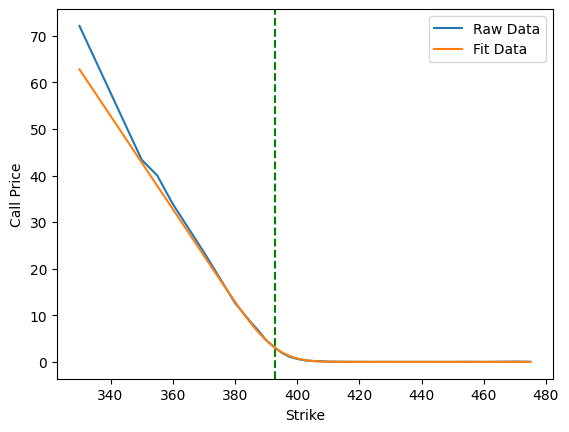

In [10]:
plt.plot(strikes, call_prices, label="Raw Data")
plt.plot(strike_space, bs_call(current_price, strike_space, T, r, sigma), label="Fit Data")
plt.ylabel("Call Price")
plt.xlabel("Strike")
plt.axvline(current_price, c="g", ls="--")
plt.legend()

## Determine the risk-neutral probability density

In [11]:
fit_spline = scipy.interpolate.make_interp_spline(strike_space, bs_call(current_price, strike_space, T, r, sigma))
risk_neutral_density = fit_spline.derivative(2)(strike_space) * np.exp(r * T)

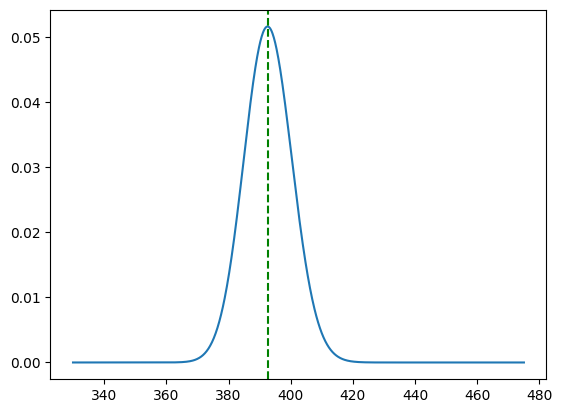

In [12]:
plt.plot(strike_space, risk_neutral_density)
plt.axvline(current_price, c="g", ls="--")

## Showing the density for multiple dates

In [13]:
from predictlib import *

In [14]:
ticker = yf.Ticker("NVDA")
S0 = ticker.fast_info.last_price
expirations = ticker.options[:9]
r = 0.05
densities = {
    e: get_risk_neutral_density(ticker.option_chain(e).calls, S0, (date.fromisoformat(e) - date.today()).days/365, r) for e in expirations
}

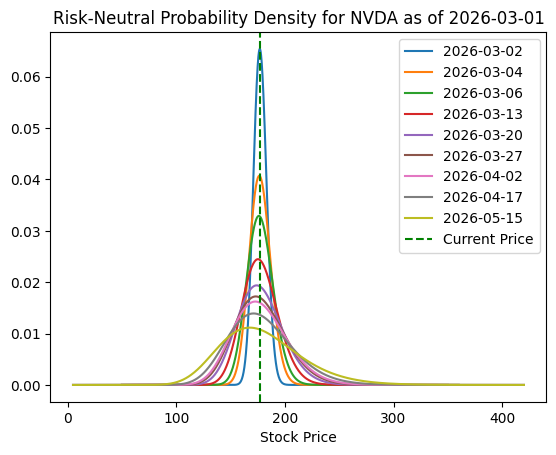

In [17]:
for e in densities:
    strikes, density = densities[e]
    plt.plot(strikes, density, label=e)

plt.title(f"Risk-Neutral Probability Density for NVDA as of {date.today()}")
plt.xlabel("Stock Price")
plt.axvline(S0, c="g", ls="--", label="Current Price")
plt.legend()